In [4]:
import rdkit
import pandas as pd
from validation import *
from rdkit.Chem import Descriptors, Crippen, Lipinski
from rdkit import Chem, DataStructs
from rdkit.Chem import AllChem
import numpy as np
import seaborn
import umap
import matplotlib.pyplot as plt
import seaborn as sns
import plotly
import ipywidgets

# Paths

In [5]:
path_smiles_task1 = '../csv_llms_task_1'
path_smiles_task2 = '../csv_llms_task_2'

# Lists

In [27]:
lst_quants = ['BF16', 'Q8', 'Q6', 'Q4']
lst_models = ['Mistral4-119B', 'Qwen3.6-35B', 'gemma-4-31B', 'gpt-oss-120B']
lst_replicas = range(1,20+1)

# Functions

In [6]:
def load_smiles_list_to_df(df, path_smiles):
    m = df['model']
    q = df['quantization']
    r = df['replica']
    
    lst_smi = pd.read_csv(f'{path_smiles}/{m}-{q}_replica_{r}.csv')['SMILES'].values.tolist()
    return lst_smi


In [105]:
def smi_number(lst_smi):
    return len(lst_smi)

def validate_smiles(lst_smi):
    lst_smi_valid = []
    for smi in lst_smi:
        try:
            mol = Chem.MolFromSmiles(smi)
            if mol is not None:
                lst_smi_valid.append(smi)
        except Exception:
            pass
    return lst_smi_valid

def smi_canonize(smi):
    mol = Chem.MolFromSmiles(smi)
    canonical = Chem.MolToSmiles(mol, canonical=True)
    return canonical

def smi_to_inchikey(smi):
    mol = Chem.MolFromSmiles(smi)
    inchikey = Chem.MolToInchiKey(mol)
    return inchikey

def smi_different(lst_smi, lst_smi_reference):
    lst_inchi     = [smi_to_inchikey(smi) for smi in lst_smi]
    lst_inchi_ref = [smi_to_inchikey(smi) for smi in lst_smi_reference]
    lst_inchi_diff = [inchi for inchi in lst_inchi if inchi not in lst_inchi_ref]
    lst_smi_diff   = [lst_smi[lst_inchi.index(key)] for key in lst_inchi_diff]
    return lst_smi_diff

def smi_unique(lst_smi):
    lst_inchi = [smi_to_inchikey(smi) for smi in lst_smi]
    lst_smi_unique = []
    set_inchi_unique = set()

    for smi, inchi in zip(lst_smi, lst_inchi):
        if inchi not in set_inchi_unique:
            set_inchi_unique.add(inchi)
            lst_smi_unique.append(smi)
    return lst_smi_unique

def smi_druglike(lst_smi, allowed_lipinski_violations=1):
    lst_smi_druglike = []
    for smi in lst_smi:
        mol = Chem.MolFromSmiles(smi)
        violations = sum([
            Descriptors.MolWt(mol) > 500,
            Crippen.MolLogP(mol) > 5,
            Lipinski.NumHDonors(mol) > 5,
            Lipinski.NumHAcceptors(mol) > 10
        ])
        
        if violations <= allowed_lipinski_violations:
            lst_smi_druglike.append(smi)
    return lst_smi_druglike

def calculate_intdiv(lst_smi):
    lst_mol = [Chem.MolFromSmiles(smi) for smi in lst_smi]
    lst_fps = [AllChem.GetMorganFingerprintAsBitVect(mol, radius=2, nBits=2048) for mol in lst_mol]
    total = len(lst_mol)

    if total >= 2:
        # Tanimoto Similarity for all unique pairs
        lst_sim = []
        
        for i in range(total):
            for j in range(i + 1, total):
                sim = DataStructs.TanimotoSimilarity(lst_fps[i], lst_fps[j])
                lst_sim.append(sim)
                
        # 3. Diversity = 1 - Average Similarity
        avg_sim = sum(lst_sim) / len(lst_sim)
        intdiv = 1.0 - avg_sim
    else:
        intdiv = None
    
    return intdiv

def calculate_metrics(df):

    df['valid smiles']  = df['smiles'].apply(validate_smiles)
    df['unique smiles'] = df['valid smiles'].apply(smi_unique)
    df['diff smiles']   = df['unique smiles'].apply(lambda x: smi_different(x, lst_smiles_prompt))
    

    df['n_smi_total']      = df['smiles'].apply(smi_number)
    df['n_smi_valid']      = df['valid smiles'].apply(smi_number)
    df['n_smi_unique']     = df['unique smiles'].apply(smi_number)
    df['n_smi_diff']       = df['diff smiles'].apply(smi_number)
    df['n_smi_invalid']    = df['n_smi_total']  - df['n_smi_valid']
    df['n_smi_duplicated'] = df['n_smi_valid']  - df['n_smi_unique']
    df['n_smi_overlap']    = df['n_smi_unique'] - df['n_smi_diff']

    # n_smi_total  = n_smi_valid  + n_smi_invalid
    # n_smi_valid  = n_smi_unique + n_smi_duplicated
    # n_smi_unique = n_smi_diff   + n_smi_overlap

    df['pct_smi_valid']      = (df['n_smi_valid']      /df['n_smi_total']).fillna(0.0)
    df['pct_smi_invalid']    = (df['n_smi_invalid']    /df['n_smi_total']).fillna(0.0)        
    df['pct_smi_duplicated'] = (df['n_smi_duplicated'] /df['n_smi_valid']).fillna(0.0)
    df['pct_smi_overlap']    = (df['n_smi_overlap']    /df['n_smi_unique']).fillna(0.0)

    df['druglike smiles']     = df['valid smiles'].apply(smi_druglike)
    df['n_smi_druglike']      = df['druglike smiles'].apply(smi_number)
    df['n_smi_notdruglike']   = df['n_smi_valid']-df['n_smi_druglike']
    df['pct_smi_druglike']    = (df['n_smi_druglike']   /df['n_smi_valid']).fillna(0.0)
    df['pct_smi_notdruglike'] = (df['n_smi_notdruglike']/df['n_smi_valid']).fillna(0.0)

    df['intdiv'] = df['valid smiles'].apply(calculate_intdiv)

    return df


In [106]:
def calc_stats(df):
    lst_cols = ['tokens_per_second', 'duration_min', 'pct_smi_valid', 'pct_smi_invalid', 'pct_smi_duplicated', 'pct_smi_overlap', 'pct_smi_druglike', 'pct_smi_notdruglike', 'intdiv']

    d_stats = {}
    for m in lst_models:
        d_stats[m] = {}
        for q in lst_quants:
            d_stats[m][q] = {}

            for col in lst_cols:
                d_stats[m][q][col] = {}

                avg = df.loc[(df['model']==m) & (df['quantization']==q)][col].mean()
                std = df.loc[(df['model']==m) & (df['quantization']==q)][col].std()
                med = df.loc[(df['model']==m) & (df['quantization']==q)][col].median()

                d_stats[m][q][col]['avg'] = float(avg)
                d_stats[m][q][col]['std'] = float(std)
                d_stats[m][q][col]['med'] = float(med)
                
    return d_stats
            

In [95]:

def plot_data(d_stats, stat, ylabel, title='', ylim=None, prompt_avg=None, prompt_std=0, scale=100):
    default_colors = plt.rcParams['axes.prop_cycle'].by_key()['color']
    alpha = 0.90

    fig, ax = plt.subplots(1,1, figsize=(10, 4))
    x=0

    for n_model,m in enumerate(lst_models):
        for n_quant, q in enumerate(lst_quants):
            if n_model==0:
                label=q
            else:
                label=''

            avg = d_stats[m][q][stat]['avg']
            std = d_stats[m][q][stat]['std']
            
            ax.bar(x=x, height=avg*scale, yerr=std*scale, color=default_colors[n_quant], label=label, alpha=alpha)
            
            x+=1
        x+=1

    ax.set_xticks([2.5-1, 7.5-1, 12.5-1, 17.5-1, 20])

    if prompt_avg is not None:
        ax.bar(x=x, height=prompt_avg*scale, yerr=prompt_std, color=default_colors[n_quant+1], label='Prompt', alpha=alpha)
        ax.set_xticklabels(lst_models+['Prompt'], fontsize=14)
    else:
        ax.set_xticklabels(lst_models+[' '], fontsize=14)

    
    

    ax.set_ylabel(f'\n{ylabel}', fontsize=15, fontweight='bold')
    if ylim is not None:
        ax.set_ylim(ylim)
        
    ax.legend(bbox_to_anchor=(1.00, 1.00), loc="upper left", fontsize=15)
    ax.tick_params(axis='y', labelsize=14)

    ax.set_title(title, fontsize=16)

    plt.show()

In [ ]:
def calc_umap(d_smiles, q, n_neighbors=15):

    reducer = umap.UMAP(
        n_neighbors=n_neighbors,    # Ajuste este valor (ex: 5 a 30). Como você tem poucas moléculas (69), um valor menor (ex: 5 ou 10) pode revelar mais estrutura local.
        min_dist=0.1,      # Controla o quão agrupados os pontos ficam no gráfico
        metric='jaccard',  # Ideal para fingerprints binários
        random_state=42    # Para reprodutibilidade
    )


    lst_smiles = lst_smiles_prompt.copy()
    for model in lst_models:
        lst_smiles += d_smiles[model][q]
        
    print(len(lst_smiles))

    lst_mols = [Chem.MolFromSmiles(m) for m in lst_smiles if m]
    lst_fps  = [AllChem.GetMorganFingerprintAsBitVect(mol, radius=2, nBits=2048) for mol in lst_mols]

    embedding = reducer.fit_transform(lst_fps)


    i=0
    lst_index  = ['prompt']*69
    i+=1
    for m in lst_models:
        lst_index += [m]*len(d_smiles[m][q])
        i+=1


    df = pd.DataFrame(embedding, columns=['UMAP_1', 'UMAP_2'])
    df['model'] = lst_index

    return df

In [119]:
def tanimoto_similarities(lst_smi, lst_smi_prompt):
    lst_mol_prompt = [Chem.MolFromSmiles(smi) for smi in lst_smi_prompt]
    lst_fps_prompt = [AllChem.GetMorganFingerprintAsBitVect(mol, radius=2, nBits=2048) for mol in lst_mol_prompt]
    total_prompt = len(lst_smi_prompt)

    lst_mol = [Chem.MolFromSmiles(smi) for smi in lst_smi]
    lst_fps = [AllChem.GetMorganFingerprintAsBitVect(mol, radius=2, nBits=2048) for mol in lst_mol]
    total = len(lst_smi)

    d = {}
    d['all'] = []
    d['avg'] = []
    d['med'] = []
    d['max'] = []

    for m1 in lst_fps:
        lst_sim = []
        for m2 in lst_fps_prompt:
            sim = DataStructs.TanimotoSimilarity(m1, m2)
            lst_sim.append(sim)

        d['all'] += lst_sim
        d['avg'].append(float(np.average(np.array(lst_sim))))
        d['med'].append(float(np.median(np.array(lst_sim))))
        d['max'].append(float(np.max(np.array(lst_sim))))
    return d

    
            

In [120]:
df_task1['valid smiles'].apply(lambda x: tanimoto_similarities(lst_smi=x, lst_smi_prompt=lst_smiles_prompt))

0      {'all': [0.0875, 0.09473684210526316, 0.117647...
1      {'all': [0.05194805194805195, 0.06521739130434...
2      {'all': [0.0875, 0.09473684210526316, 0.117647...
3      {'all': [0.10666666666666667, 0.08695652173913...
4      {'all': [0.15, 0.11224489795918367, 0.15714285...
                             ...                        
395    {'all': [0.10666666666666667, 0.08695652173913...
396    {'all': [0.12987012987012986, 0.10638297872340...
397    {'all': [0.08536585365853659, 0.11578947368421...
398         {'all': [], 'avg': [], 'med': [], 'max': []}
399    {'all': [0.03125, 0.012195121951219513, 0.0377...
Name: valid smiles, Length: 400, dtype: object

In [ ]:
def pairwise_tanimoto_stats(d_smiles):
    d = {}
    
    lst_smi_prompt = d_smiles['prompt']
    lst_mol_prompt = [Chem.MolFromSmiles(smi) for smi in lst_smi_prompt]
    lst_fps_prompt = [AllChem.GetMorganFingerprintAsBitVect(mol, radius=2, nBits=2048) for mol in lst_mol_prompt]
    total_prompt = len(lst_smi_prompt)
    
    for q in lst_quants:
        d[q] = {}
        
        for m in lst_models:
            d[q][m] = {}
            d[q][m]['all'] = []
            d[q][m]['avg'] = []
            d[q][m]['max'] = []
            d[q][m]['med'] = []
            
            
            lst_smi = d_smiles[m][q]
            lst_mol = [Chem.MolFromSmiles(smi) for smi in lst_smi]
            lst_fps = [AllChem.GetMorganFingerprintAsBitVect(mol, radius=2, nBits=2048) for mol in lst_mol]
            total = len(lst_smi)
    
    
            for m1 in lst_fps:
                lst_sim = []
                for m2 in lst_fps_prompt:
                    sim = DataStructs.TanimotoSimilarity(m1, m2)
                    lst_sim.append(sim)
                    
                d[q][m]['all'] += lst_sim
                d[q][m]['avg'].append(float(np.average(np.array(lst_sim))))
                d[q][m]['max'].append(float(np.max(np.array(lst_sim))))
                d[q][m]['med'].append(float(np.median(np.array(lst_sim))))
    return d

# **PROMPT**

In [96]:
lst_smiles_prompt = pd.read_csv('smiles_prompt.csv')['SMILES'].values.tolist()

n_smi_total = len(lst_smiles_prompt)
lst_valid_smi = validate_smiles(lst_smiles_prompt)
n_smi_valid = len(lst_valid_smi)
n_smi_druglike = len(smi_druglike(lst_valid_smi))
intdiv = calculate_intdiv(lst_valid_smi)

d_prompt = {'n_smi_total':n_smi_total, 'n_smi_valid':n_smi_valid,
            'n_smi_druglike' : n_smi_druglike,
            'n_smi_notdruglike' : n_smi_valid - n_smi_druglike,
            'intdiv':intdiv,
           }

d_prompt['pct_smi_valid']    = d_prompt['n_smi_valid']/d_prompt['n_smi_total']
d_prompt['pct_smi_druglike'] = d_prompt['n_smi_druglike']/d_prompt['n_smi_valid']
d_prompt['pct_smi_notdruglike'] = d_prompt['n_smi_notdruglike']/d_prompt['n_smi_valid']


In [16]:
lst_smiles_prompt

['O=S(C1=CC=CC(NC2=NC(NC3=CC=C(C=C3)OCCN4CCCC4)=NC=C2C)=C1)(NC(C)(C)C)=O',
 'O=C(C1=CC=C(C(OC)=C1)NC2=NC=C(N(C3=O)C)C(N([C@@H]3CC)C(C)C)=N2)N[C@H]4CC[C@@H](CC4)N5CCN(CC5)CC6CC6',
 'OCCOC1=CC2=C(N=CN=C2NC3=CC=CC(C#C)=C3)C=C1OCCOC',
 'O=C(NC1=C(C=C2C(C(NC3=CC=C(C(Cl)=C3)F)=NC=N2)=C1)OCCCN4CCOCC4)C=C',
 'O=C(C1=C(C)N(CC(C)(O)C)N(C2=CC=CC=C2)C1=O)NC3=NC=C(OC4=CC=NC5=CC(OC)=CC=C45)C=C3',
 'O=C(NC1=CC=C(C=C1F)OC2=CC(NC(N3CCC(CC3)N4CCN(CC4)C)=O)=NC=C2)C5(CC5)C(NC6=CC=C(C=C6)F)=O',
 'N#CC1=C(C2=CC(NC(/C=C/CN(C)C)=O)=C(OCC)C=C2N=C1)NC3=CC(Cl)=C(C=C3)F',
 'O=C(NC1=C(C=C2C(C(NC3=CC(Cl)=C(C=C3)F)=NC=N2)=C1)O[C@H]4CCOC4)/C=C/CN(C)C',
 'ClC1=C(C=CC(NC2=NC=NC3=C2C=C(C(OC)=C3)OCCCN4CCOCC4)=C1)F',
 'O/N=C1CCC2=CC(C3=C(NC(C4=CC=C(C=C4)OCCN(C)C)=N3)C5=CC=NC=C5)=CC=C/12',
 'FC(C(Cl)=CC=C1)=C1O[C@H](CC2)CC[C@@]2(C(O)=O)CC3=CC=CC(NC4=NC=CS4)=N3',
 'O=S(C1=CC=CC(NC2=NC(NC3=CC=C(C=C3)N4CCN(CC4)C)=NC=C2C)=C1)(NC(C)(C)C)=O',
 'CN1CCN(C2=CC=C(C=C2)NC3=NC=C(C(OC4=CC(NC(C=C)=O)=CC=C4)=N3)Cl)CC1',
 'O=C(/C=C/CN1CCC

In [17]:
d_prompt

{'n_smi_total': 69, 'n_smi_valid': 69, 'pct_smi_valid': 1.0}

# **TASK1**

## 1. Load raw data

In [107]:
df_task1 = pd.read_csv('raw_data_task1.csv')
df_task1['replica'] = df_task1.groupby(['model', 'quantization']).cumcount() + 1 # annotates the replica number
df_task1['smiles'] = df_task1.apply(lambda x: load_smiles_list_to_df(df=x, path_smiles=path_smiles_task1), axis=1)
df_task1


,quantization,model,tokens_per_second,duration_min,replica,smiles
0,BF16,gpt-oss-120B,14.255372,8.306117,1,"[O=C(C)Oc1ccccc1C(=O)O, CN1C=NC2=C1C(=O)N(C(=O..."
1,BF16,gpt-oss-120B,14.344542,6.297450,2,"[CC(C)NCC(O)CO, c1ccccc1, c1ccncc1, c1cc(ccc1)..."
2,BF16,gpt-oss-120B,14.392826,3.095300,3,"[CC(=O)Oc1ccccc1C(=O)O, CC(C)CC1=CC=C(C=C1)C(C..."
3,BF16,gpt-oss-120B,14.016174,13.825083,4,"[CC(=O)NC1=CC=C(O)C=C1, CC(C)Cc1ccc(cc1)C(C)C(..."
4,BF16,gpt-oss-120B,13.866866,11.298450,5,"[CC(C)NCC(O)COc1ccccc1, c1ccc(Cl)cc1C(=O)O, Cn..."
...,...,...,...,...,...,...
395,BF16,Mistral4-119B,4.576826,22.101167,21,"[CC(=O)Nc1ccc(O)cc1, CC(=O)OC1=CC=CC=C1C(=O)O,..."
396,BF16,Mistral4-119B,4.576121,21.860533,22,"[CC1=CC=CC=C1C(=O)OCC, CC1(C)C2=CC=CC=C2C(=O)N..."
397,BF16,Mistral4-119B,4.598729,4.447450,23,"[CCOc1ccc2c(c1)C(=O)c1[nH]c3ccccc3c21c1ccccc1,..."
398,BF16,Mistral4-119B,4.597749,6.884150,24,[]


In [108]:
df_task1 = calculate_metrics(df_task1)
df_task1

,quantization,model,tokens_per_second,duration_min,replica,smiles,valid smiles,unique smiles,diff smiles,n_smi_total,...,pct_smi_valid,pct_smi_invalid,pct_smi_duplicated,pct_smi_overlap,druglike smiles,n_smi_druglike,n_smi_notdruglike,pct_smi_druglike,pct_smi_notdruglike,intdiv
0,BF16,gpt-oss-120B,14.255372,8.306117,1,"[O=C(C)Oc1ccccc1C(=O)O, CN1C=NC2=C1C(=O)N(C(=O...","[O=C(C)Oc1ccccc1C(=O)O, CN1C=NC2=C1C(=O)N(C(=O...","[O=C(C)Oc1ccccc1C(=O)O, CN1C=NC2=C1C(=O)N(C(=O...","[O=C(C)Oc1ccccc1C(=O)O, CN1C=NC2=C1C(=O)N(C(=O...",20,...,0.850000,0.150000,0.0000,0.0,"[O=C(C)Oc1ccccc1C(=O)O, CN1C=NC2=C1C(=O)N(C(=O...",17,0,1.0,0.0,0.812533
1,BF16,gpt-oss-120B,14.344542,6.297450,2,"[CC(C)NCC(O)CO, c1ccccc1, c1ccncc1, c1cc(ccc1)...","[CC(C)NCC(O)CO, c1ccccc1, c1ccncc1, c1cc(ccc1)...","[CC(C)NCC(O)CO, c1ccccc1, c1ccncc1, c1cc(ccc1)...","[CC(C)NCC(O)CO, c1ccccc1, c1ccncc1, c1cc(ccc1)...",20,...,0.950000,0.050000,0.0000,0.0,"[CC(C)NCC(O)CO, c1ccccc1, c1ccncc1, c1cc(ccc1)...",19,0,1.0,0.0,0.838292
2,BF16,gpt-oss-120B,14.392826,3.095300,3,"[CC(=O)Oc1ccccc1C(=O)O, CC(C)CC1=CC=C(C=C1)C(C...","[CC(=O)Oc1ccccc1C(=O)O, CC(C)CC1=CC=C(C=C1)C(C...","[CC(=O)Oc1ccccc1C(=O)O, CC(C)CC1=CC=C(C=C1)C(C...","[CC(=O)Oc1ccccc1C(=O)O, CC(C)CC1=CC=C(C=C1)C(C...",20,...,1.000000,0.000000,0.0000,0.0,"[CC(=O)Oc1ccccc1C(=O)O, CC(C)CC1=CC=C(C=C1)C(C...",20,0,1.0,0.0,0.881253
3,BF16,gpt-oss-120B,14.016174,13.825083,4,"[CC(=O)NC1=CC=C(O)C=C1, CC(C)Cc1ccc(cc1)C(C)C(...","[CC(=O)NC1=CC=C(O)C=C1, CC(C)Cc1ccc(cc1)C(C)C(...","[CC(=O)NC1=CC=C(O)C=C1, CC(C)Cc1ccc(cc1)C(C)C(...","[CC(=O)NC1=CC=C(O)C=C1, CC(C)Cc1ccc(cc1)C(C)C(...",20,...,0.850000,0.150000,0.0000,0.0,"[CC(=O)NC1=CC=C(O)C=C1, CC(C)Cc1ccc(cc1)C(C)C(...",17,0,1.0,0.0,0.840247
4,BF16,gpt-oss-120B,13.866866,11.298450,5,"[CC(C)NCC(O)COc1ccccc1, c1ccc(Cl)cc1C(=O)O, Cn...","[CC(C)NCC(O)COc1ccccc1, c1ccc(Cl)cc1C(=O)O, c1...","[CC(C)NCC(O)COc1ccccc1, c1ccc(Cl)cc1C(=O)O, c1...","[CC(C)NCC(O)COc1ccccc1, c1ccc(Cl)cc1C(=O)O, c1...",20,...,0.950000,0.050000,0.0000,0.0,"[CC(C)NCC(O)COc1ccccc1, c1ccc(Cl)cc1C(=O)O, c1...",19,0,1.0,0.0,0.890145
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
395,BF16,Mistral4-119B,4.576826,22.101167,21,"[CC(=O)Nc1ccc(O)cc1, CC(=O)OC1=CC=CC=C1C(=O)O,...","[CC(=O)Nc1ccc(O)cc1, CC(=O)OC1=CC=CC=C1C(=O)O,...","[CC(=O)Nc1ccc(O)cc1, CC(=O)OC1=CC=CC=C1C(=O)O,...","[CC(=O)Nc1ccc(O)cc1, CC(=O)OC1=CC=CC=C1C(=O)O,...",21,...,0.761905,0.238095,0.0000,0.0,"[CC(=O)Nc1ccc(O)cc1, CC(=O)OC1=CC=CC=C1C(=O)O,...",16,0,1.0,0.0,0.867857
396,BF16,Mistral4-119B,4.576121,21.860533,22,"[CC1=CC=CC=C1C(=O)OCC, CC1(C)C2=CC=CC=C2C(=O)N...","[CC1=CC=CC=C1C(=O)OCC, C1=CC=CC=C1C(=O)NCC2=CC...","[CC1=CC=CC=C1C(=O)OCC, C1=CC=CC=C1C(=O)NCC2=CC...","[CC1=CC=CC=C1C(=O)OCC, C1=CC=CC=C1C(=O)NCC2=CC...",19,...,0.842105,0.157895,0.0625,0.0,"[CC1=CC=CC=C1C(=O)OCC, C1=CC=CC=C1C(=O)NCC2=CC...",16,0,1.0,0.0,0.795691
397,BF16,Mistral4-119B,4.598729,4.447450,23,"[CCOc1ccc2c(c1)C(=O)c1[nH]c3ccccc3c21c1ccccc1,...","[CC(=O)Nc1ccc(O)cc1C(=O)O, Cc1ccccc1N2C(=O)CCC...","[CC(=O)Nc1ccc(O)cc1C(=O)O, Cc1ccccc1N2C(=O)CCC...","[CC(=O)Nc1ccc(O)cc1C(=O)O, Cc1ccccc1N2C(=O)CCC...",21,...,0.952381,0.047619,0.1000,0.0,"[CC(=O)Nc1ccc(O)cc1C(=O)O, Cc1ccccc1N2C(=O)CCC...",20,0,1.0,0.0,0.763079
398,BF16,Mistral4-119B,4.597749,6.884150,24,[],[],[],[],0,...,0.000000,0.000000,0.0000,0.0,[],0,0,0.0,0.0,NaN


In [109]:
d_stats_task1 = calc_stats(df_task1)
d_stats_task1

{'Mistral4-119B': {'BF16': {'tokens_per_second': {'avg': 4.433329837339215,
    'std': 0.34672531151621405,
    'med': 4.576825955601774},
   'duration_min': {'avg': 13.764698666666666,
    'std': 7.617711911690545,
    'med': 12.62805},
   'pct_smi_valid': {'avg': 0.76065664160401,
    'std': 0.29830643146192304,
    'med': 0.8421052631578947},
   'pct_smi_invalid': {'avg': 0.11934335839598997,
    'std': 0.09392851883504014,
    'med': 0.15},
   'pct_smi_duplicated': {'avg': 0.020254385964912282,
    'std': 0.040947103145109034,
    'med': 0.0},
   'pct_smi_overlap': {'avg': 0.0, 'std': 0.0, 'med': 0.0},
   'pct_smi_druglike': {'avg': 0.8773333333333333,
    'std': 0.3309246305597562,
    'med': 1.0},
   'pct_smi_notdruglike': {'avg': 0.0026666666666666666,
    'std': 0.013333333333333334,
    'med': 0.0},
   'intdiv': {'avg': 0.8433075520556198,
    'std': 0.05130848870458531,
    'med': 0.8570633415280835}},
  'Q8': {'tokens_per_second': {'avg': 7.92295836850192,
    'std': 0.50842

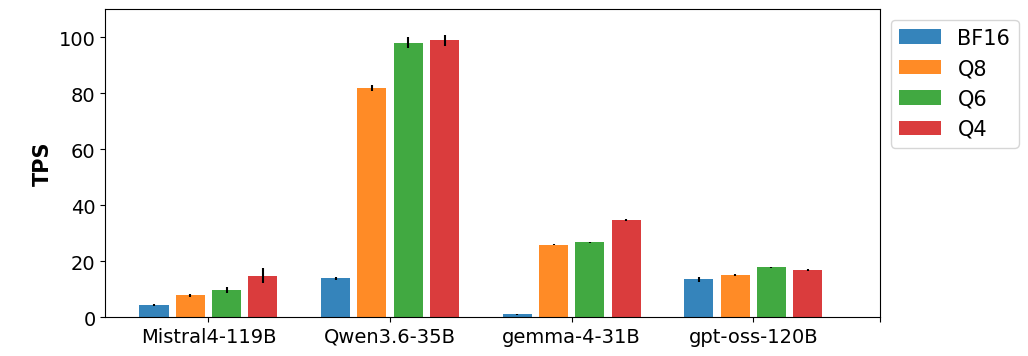

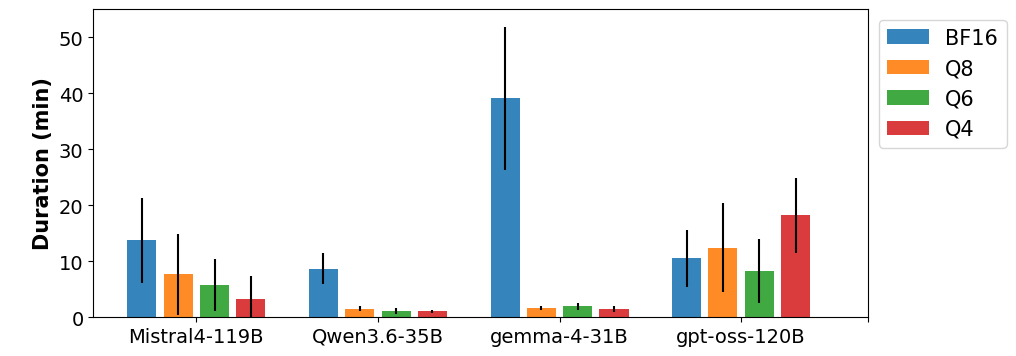

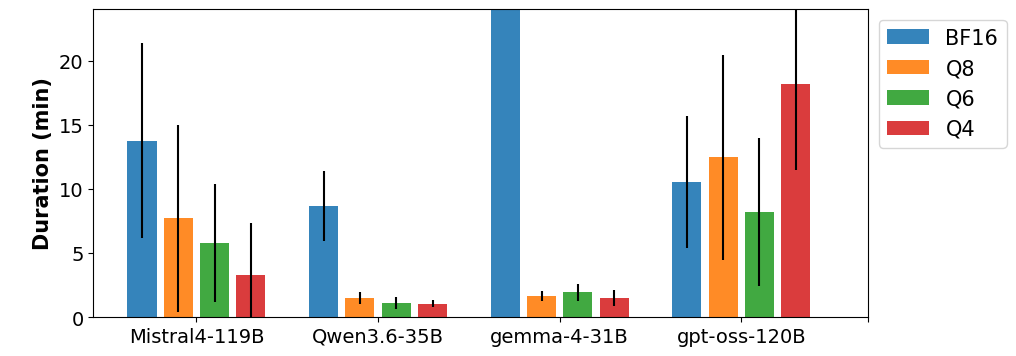

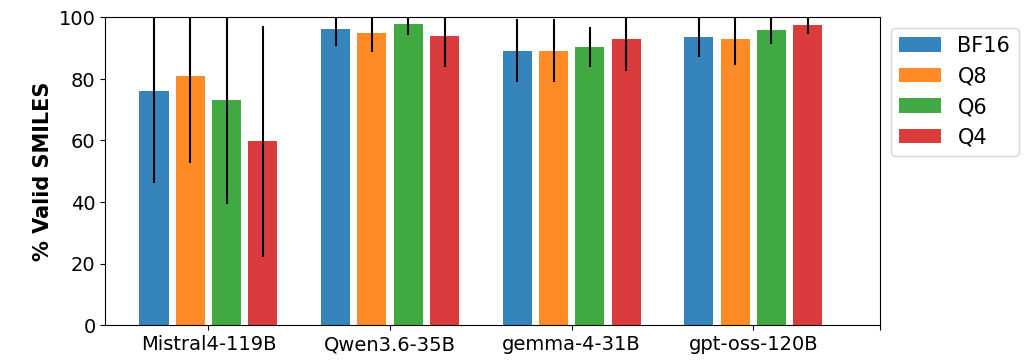

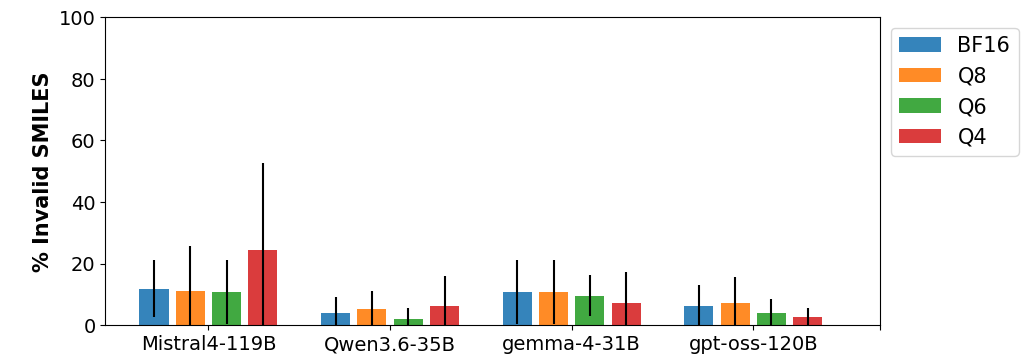

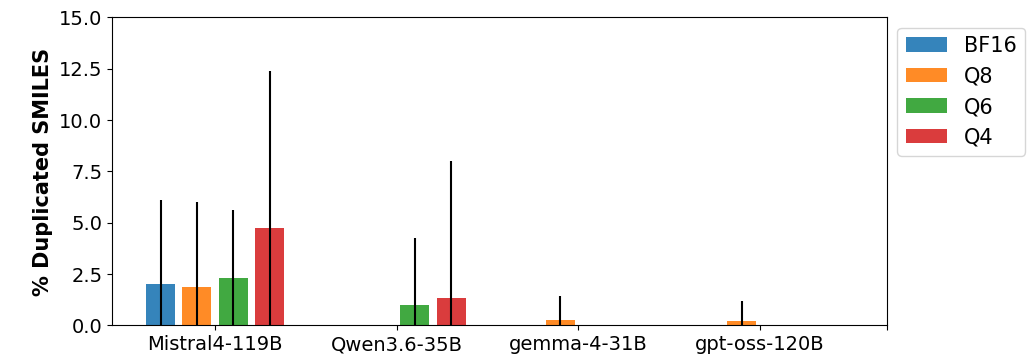

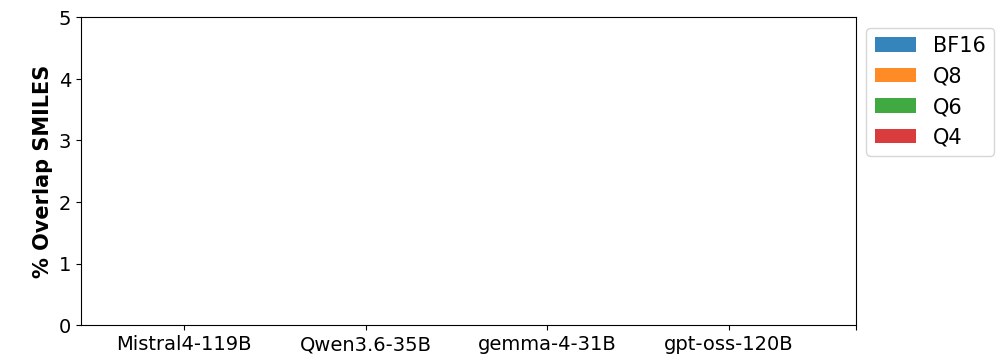

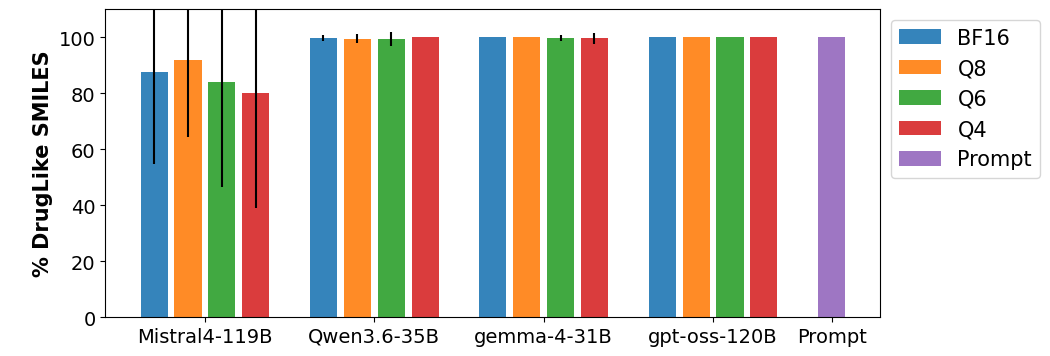

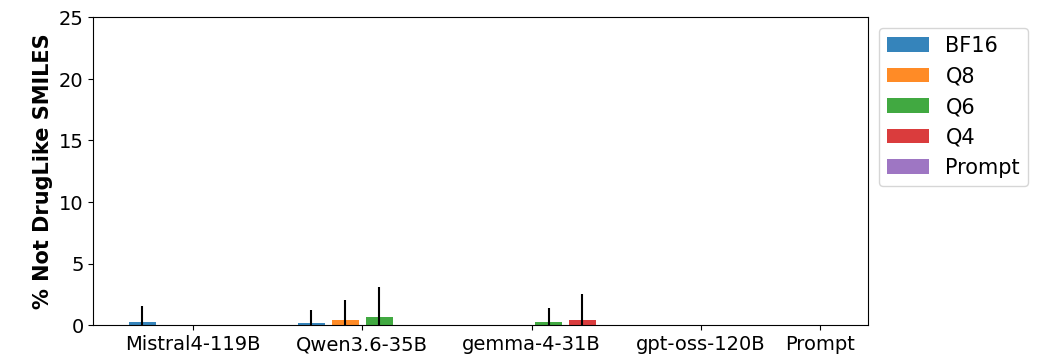

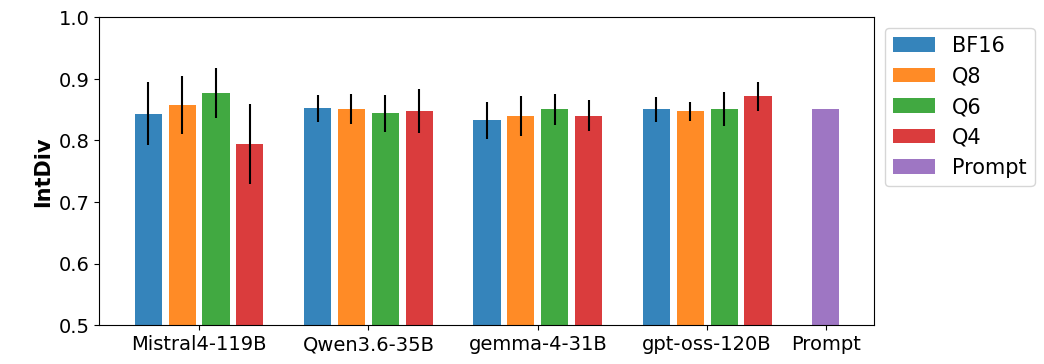

In [118]:
plot_data(d_stats=d_stats_task1, stat='tokens_per_second', ylabel='TPS'           , ylim=[0,110], prompt_avg=None, prompt_std=0.0, scale=1)
plot_data(d_stats=d_stats_task1, stat='duration_min',      ylabel='Duration (min)'  , ylim=[0,55],  prompt_avg=None, prompt_std=0.0, scale=1)
plot_data(d_stats=d_stats_task1, stat='duration_min',      ylabel='Duration (min)'  , ylim=[0,24],  prompt_avg=None, prompt_std=0.0, scale=1)

plot_data(d_stats=d_stats_task1, stat='pct_smi_valid',     ylabel='% Valid SMILES'      , ylim=[0,100],  prompt_avg=None, prompt_std=0.0, scale=100)
plot_data(d_stats=d_stats_task1, stat='pct_smi_invalid',   ylabel='% Invalid SMILES'    , ylim=[0,100],  prompt_avg=None, prompt_std=0.0, scale=100)

plot_data(d_stats=d_stats_task1, stat='pct_smi_duplicated',ylabel='% Duplicated SMILES' , ylim=[0,15],  prompt_avg=None, prompt_std=0.0, scale=100)
plot_data(d_stats=d_stats_task1, stat='pct_smi_overlap',   ylabel='% Overlap SMILES'    , ylim=[0,5],  prompt_avg=None, prompt_std=0.0, scale=100)

plot_data(d_stats=d_stats_task1, stat='pct_smi_druglike',     ylabel='% DrugLike SMILES', ylim=[0,110], prompt_avg=d_prompt['pct_smi_druglike'], prompt_std=0.0, scale=100)
plot_data(d_stats=d_stats_task1, stat='pct_smi_notdruglike',  ylabel='% Not DrugLike SMILES', ylim=[0,25], prompt_avg=d_prompt['pct_smi_notdruglike'], prompt_std=0.0, scale=100)

plot_data(d_stats=d_stats_task1, stat='intdiv',  ylabel='IntDiv', ylim=[0.5,1], prompt_avg=d_prompt['intdiv'], prompt_std=0.0, scale=1)


# TASK 2

# 1. Load raw data

In [112]:
df_task2 = pd.read_csv('raw_data_task2.csv')
df_task2['replica'] = df_task2.groupby(['model', 'quantization']).cumcount() + 1 # annotates the replica number
df_task2['smiles'] = df_task2.apply(lambda x: load_smiles_list_to_df(df=x, path_smiles=path_smiles_task2), axis=1)
df_task2


,quantization,model,tokens_per_second,duration_min,replica,smiles
0,BF16,gpt-oss-120B,14.209755,26.579133,1,[O=S(C1=CC=CC(NC2=NC(NC3=CC=C(C=C3)OCCN4CCOCC4...
1,BF16,gpt-oss-120B,14.065747,36.731050,2,[O=C(Nc1ccc(Cl)cc1)Nc2nc(Nc3ccccc3)nc(Nc4ccc(F...
2,BF16,gpt-oss-120B,14.298367,19.241883,3,[O=S(=O)(N(C)C1=CC=CC=C1)C2=CC=CC(NC(=O)C3=CC=...
3,BF16,gpt-oss-120B,14.131008,36.153983,4,[O=S(C1=CC=CC(NC2=NC(NC3=CC=C(C=C3)OCCN4CCOCC4...
4,BF16,gpt-oss-120B,14.098691,30.805183,5,[O=S(C1=CC=CC(NC2=NC(NC3=CC=C(C=C3)OCCN4CCOCC4...
...,...,...,...,...,...,...
395,BF16,Mistral4-119B,4.709737,8.291433,21,[O=S(C1=CC=CC(NC2=NC(NC3=CC=C(CC)C=C3)=NC=C2C)...
396,BF16,Mistral4-119B,4.711069,8.434183,22,[CN1CCN(C2=CC=C(Cl)C=C2)C3=CC=C(C=C3)NC(C4)C(=...
397,BF16,Mistral4-119B,4.605285,41.774433,23,"[O=C(NC1=CC=CC=C1)C2=NC=CC=N2, O=S(NC1=CC=CC=C..."
398,BF16,Mistral4-119B,4.720910,3.344550,24,"[CN1CCN(C2=CC=CC=C2)CCC1, N#CC1=CC=CC=C1NC2=CC..."


In [113]:
df_task2 = calculate_metrics(df_task2)
df_task2

,quantization,model,tokens_per_second,duration_min,replica,smiles,valid smiles,unique smiles,diff smiles,n_smi_total,...,pct_smi_valid,pct_smi_invalid,pct_smi_duplicated,pct_smi_overlap,druglike smiles,n_smi_druglike,n_smi_notdruglike,pct_smi_druglike,pct_smi_notdruglike,intdiv
0,BF16,gpt-oss-120B,14.209755,26.579133,1,[O=S(C1=CC=CC(NC2=NC(NC3=CC=C(C=C3)OCCN4CCOCC4...,[O=S(C1=CC=CC(NC2=NC(NC3=CC=C(C=C3)OCCN4CCOCC4...,[O=S(C1=CC=CC(NC2=NC(NC3=CC=C(C=C3)OCCN4CCOCC4...,[O=S(C1=CC=CC(NC2=NC(NC3=CC=C(C=C3)OCCN4CCOCC4...,20,...,0.950000,0.050000,0.0,0.0,[O=S(C1=CC=CC(NC2=NC(NC3=CC=C(C=C3)OCCN4CCOCC4...,17,2,0.894737,0.105263,0.813654
1,BF16,gpt-oss-120B,14.065747,36.731050,2,[O=C(Nc1ccc(Cl)cc1)Nc2nc(Nc3ccccc3)nc(Nc4ccc(F...,[O=C(Nc1ccc(Cl)cc1)Nc2nc(Nc3ccccc3)nc(Nc4ccc(F...,[O=C(Nc1ccc(Cl)cc1)Nc2nc(Nc3ccccc3)nc(Nc4ccc(F...,[O=C(Nc1ccc(Cl)cc1)Nc2nc(Nc3ccccc3)nc(Nc4ccc(F...,20,...,0.750000,0.250000,0.0,0.0,[O=C(Nc1ccc(Cl)cc1)Nc2nc(Nc3ccccc3)nc(Nc4ccc(F...,15,0,1.000000,0.000000,0.848630
2,BF16,gpt-oss-120B,14.298367,19.241883,3,[O=S(=O)(N(C)C1=CC=CC=C1)C2=CC=CC(NC(=O)C3=CC=...,[O=S(=O)(N(C)C1=CC=CC=C1)C2=CC=CC(NC(=O)C3=CC=...,[O=S(=O)(N(C)C1=CC=CC=C1)C2=CC=CC(NC(=O)C3=CC=...,[O=S(=O)(N(C)C1=CC=CC=C1)C2=CC=CC(NC(=O)C3=CC=...,20,...,0.900000,0.100000,0.0,0.0,[O=S(=O)(N(C)C1=CC=CC=C1)C2=CC=CC(NC(=O)C3=CC=...,18,0,1.000000,0.000000,0.823012
3,BF16,gpt-oss-120B,14.131008,36.153983,4,[O=S(C1=CC=CC(NC2=NC(NC3=CC=C(C=C3)OCCN4CCOCC4...,[O=S(C1=CC=CC(NC2=NC(NC3=CC=C(C=C3)OCCN4CCOCC4...,[O=S(C1=CC=CC(NC2=NC(NC3=CC=C(C=C3)OCCN4CCOCC4...,[O=S(C1=CC=CC(NC2=NC(NC3=CC=C(C=C3)OCCN4CCOCC4...,20,...,1.000000,0.000000,0.0,0.0,[O=S(C1=CC=CC(NC2=NC(NC3=CC=C(C=C3)OCCN4CCOCC4...,17,3,0.850000,0.150000,0.805525
4,BF16,gpt-oss-120B,14.098691,30.805183,5,[O=S(C1=CC=CC(NC2=NC(NC3=CC=C(C=C3)OCCN4CCOCC4...,[O=S(C1=CC=CC(NC2=NC(NC3=CC=C(C=C3)OCCN4CCOCC4...,[O=S(C1=CC=CC(NC2=NC(NC3=CC=C(C=C3)OCCN4CCOCC4...,[O=S(C1=CC=CC(NC2=NC(NC3=CC=C(C=C3)OCCN4CCOCC4...,20,...,0.950000,0.050000,0.0,0.0,[O=S(C1=CC=CC(NC2=NC(NC3=CC=C(C=C3)OCCN4CCOCC4...,14,5,0.736842,0.263158,0.825582
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
395,BF16,Mistral4-119B,4.709737,8.291433,21,[O=S(C1=CC=CC(NC2=NC(NC3=CC=C(CC)C=C3)=NC=C2C)...,[O=S(C1=CC=CC(NC2=NC(NC3=CC=C(CC)C=C3)=NC=C2C)...,[O=S(C1=CC=CC(NC2=NC(NC3=CC=C(CC)C=C3)=NC=C2C)...,[O=S(C1=CC=CC(NC2=NC(NC3=CC=C(CC)C=C3)=NC=C2C)...,30,...,0.500000,0.500000,0.0,0.0,[O=S(C1=CC=CC(NC2=NC(NC3=CC=C(CC)C=C3)=NC=C2C)...,14,1,0.933333,0.066667,0.822359
396,BF16,Mistral4-119B,4.711069,8.434183,22,[CN1CCN(C2=CC=C(Cl)C=C2)C3=CC=C(C=C3)NC(C4)C(=...,"[O=C(NC1=CC=C(C=C1)F)N2CCC(CC2)N3CCCCC3, CC1=C...","[O=C(NC1=CC=C(C=C1)F)N2CCC(CC2)N3CCCCC3, CC1=C...","[O=C(NC1=CC=C(C=C1)F)N2CCC(CC2)N3CCCCC3, CC1=C...",19,...,0.526316,0.473684,0.0,0.0,"[O=C(NC1=CC=C(C=C1)F)N2CCC(CC2)N3CCCCC3, CC1=C...",10,0,1.000000,0.000000,0.839137
397,BF16,Mistral4-119B,4.605285,41.774433,23,"[O=C(NC1=CC=CC=C1)C2=NC=CC=N2, O=S(NC1=CC=CC=C...","[O=C(NC1=CC=CC=C1)C2=NC=CC=N2, O=S(NC1=CC=CC=C...","[O=C(NC1=CC=CC=C1)C2=NC=CC=N2, O=S(NC1=CC=CC=C...","[O=C(NC1=CC=CC=C1)C2=NC=CC=N2, O=S(NC1=CC=CC=C...",20,...,0.150000,0.850000,0.0,0.0,"[O=C(NC1=CC=CC=C1)C2=NC=CC=N2, O=S(NC1=CC=CC=C...",3,0,1.000000,0.000000,0.787865
398,BF16,Mistral4-119B,4.720910,3.344550,24,"[CN1CCN(C2=CC=CC=C2)CCC1, N#CC1=CC=CC=C1NC2=CC...","[CN1CCN(C2=CC=CC=C2)CCC1, N#CC1=CC=CC=C1NC2=CC...","[CN1CCN(C2=CC=CC=C2)CCC1, N#CC1=CC=CC=C1NC2=CC...","[CN1CCN(C2=CC=CC=C2)CCC1, N#CC1=CC=CC=C1NC2=CC...",19,...,0.894737,0.105263,0.0,0.0,"[CN1CCN(C2=CC=CC=C2)CCC1, N#CC1=CC=CC=C1NC2=CC...",17,0,1.000000,0.000000,0.805557


In [114]:
d_stats_task2 = calc_stats(df_task2)
d_stats_task2

{'Mistral4-119B': {'BF16': {'tokens_per_second': {'avg': 4.537699146271506,
    'std': 0.43879909588539384,
    'med': 4.7058953753537285},
   'duration_min': {'avg': 10.373424666666667,
    'std': 10.466659569543904,
    'med': 6.25005},
   'pct_smi_valid': {'avg': 0.6161938178780284,
    'std': 0.32958396864123635,
    'med': 0.75},
   'pct_smi_invalid': {'avg': 0.3038061821219716,
    'std': 0.28739048245485804,
    'med': 0.21052631578947367},
   'pct_smi_duplicated': {'avg': 0.03125885792913657,
    'std': 0.06912282571513734,
    'med': 0.0},
   'pct_smi_overlap': {'avg': 0.0, 'std': 0.0, 'med': 0.0},
   'pct_smi_druglike': {'avg': 0.9173333333333333,
    'std': 0.2764054992217051,
    'med': 1.0},
   'pct_smi_notdruglike': {'avg': 0.0026666666666666666,
    'std': 0.013333333333333332,
    'med': 0.0},
   'intdiv': {'avg': 0.797974106671446,
    'std': 0.06224438034193706,
    'med': 0.8223586833517287}},
  'Q8': {'tokens_per_second': {'avg': 7.767967174267953,
    'std': 0.4625

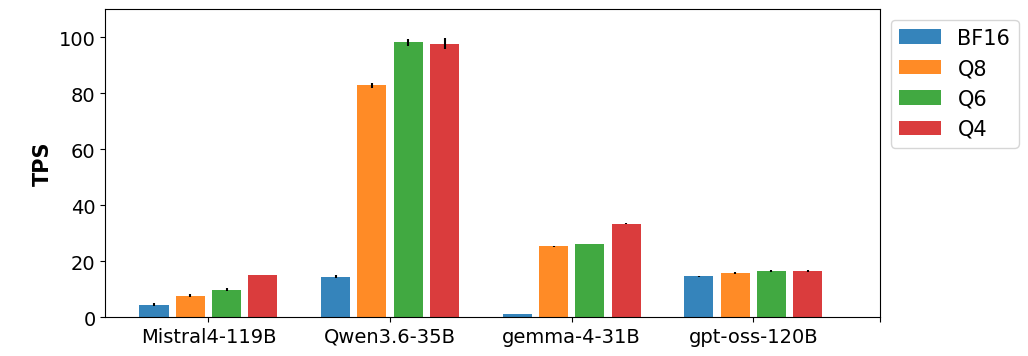

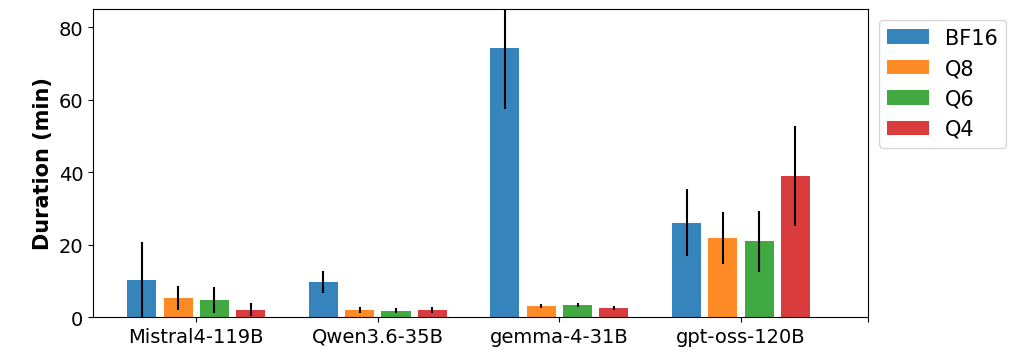

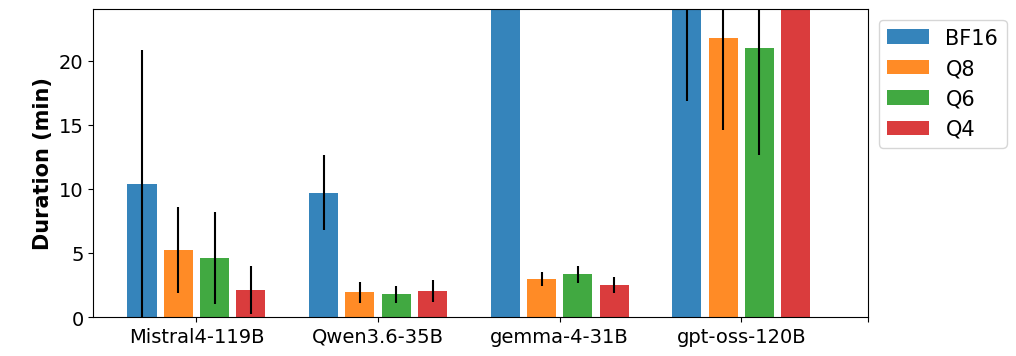

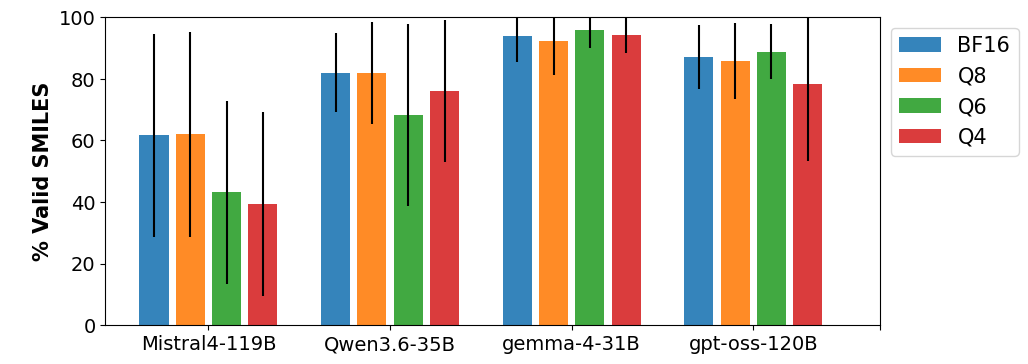

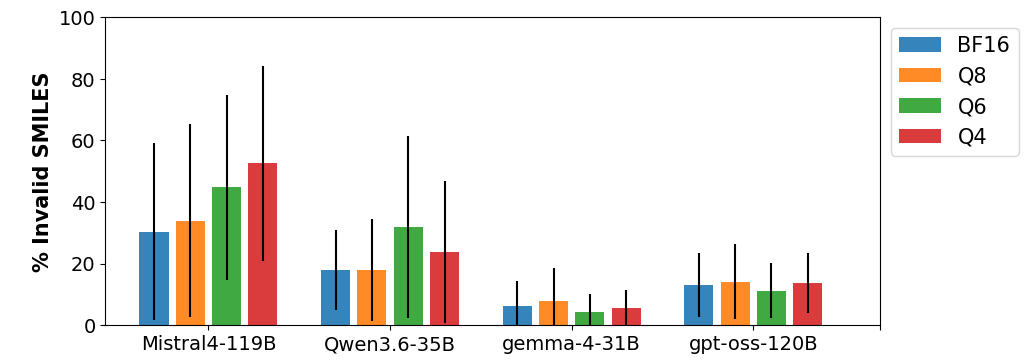

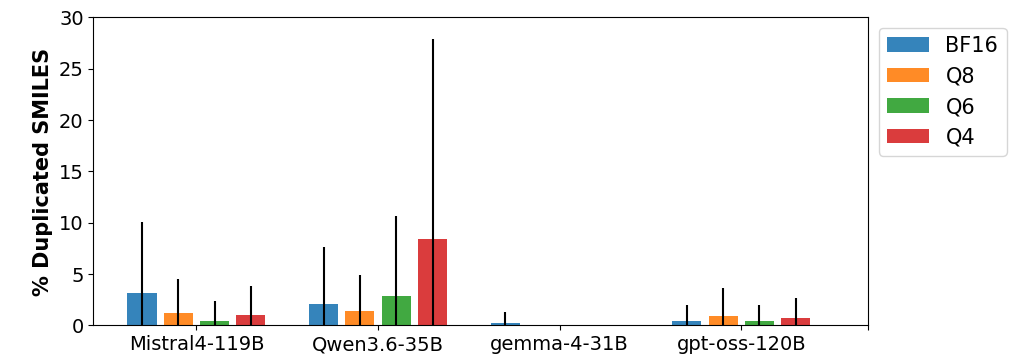

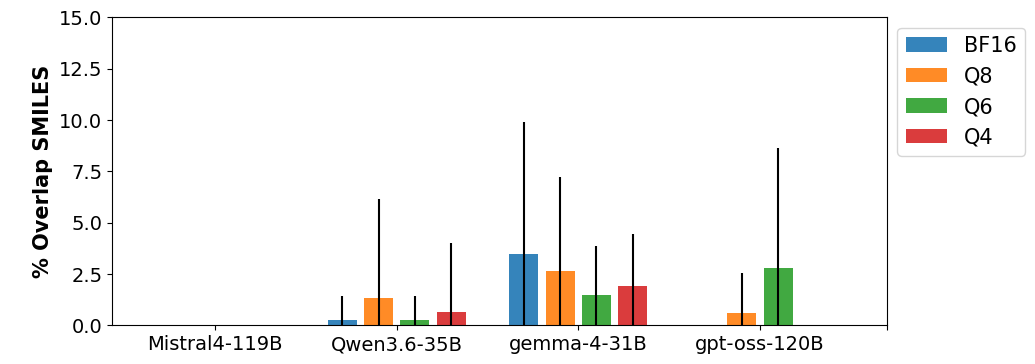

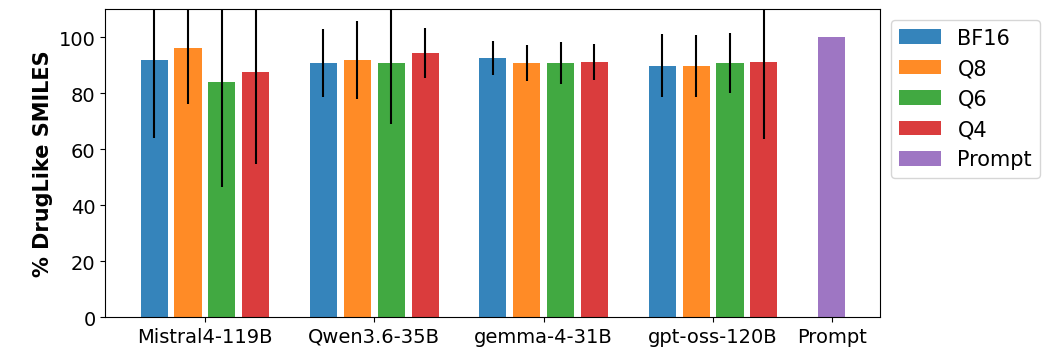

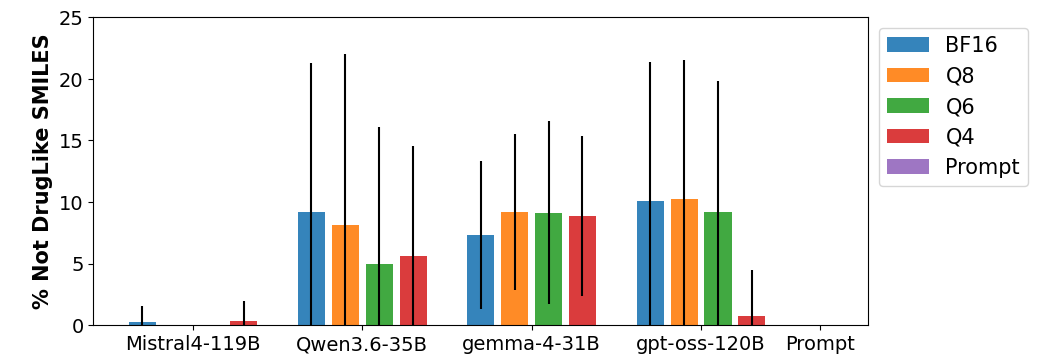

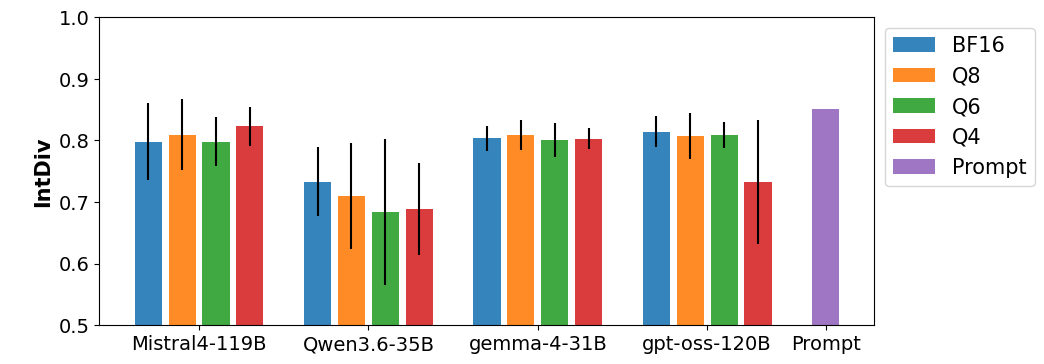

In [117]:
plot_data(d_stats=d_stats_task2, stat='tokens_per_second', ylabel='TPS'           , ylim=[0,110], prompt_avg=None, prompt_std=0.0, scale=1)
plot_data(d_stats=d_stats_task2, stat='duration_min',      ylabel='Duration (min)'  , ylim=[0,85],  prompt_avg=None, prompt_std=0.0, scale=1)
plot_data(d_stats=d_stats_task2, stat='duration_min',      ylabel='Duration (min)'  , ylim=[0,24],  prompt_avg=None, prompt_std=0.0, scale=1)

plot_data(d_stats=d_stats_task2, stat='pct_smi_valid',     ylabel='% Valid SMILES'      , ylim=[0,100],  prompt_avg=None, prompt_std=0.0, scale=100)
plot_data(d_stats=d_stats_task2, stat='pct_smi_invalid',   ylabel='% Invalid SMILES'    , ylim=[0,100],  prompt_avg=None, prompt_std=0.0, scale=100)
plot_data(d_stats=d_stats_task2, stat='pct_smi_duplicated',ylabel='% Duplicated SMILES' , ylim=[0,30],  prompt_avg=None, prompt_std=0.0, scale=100)
plot_data(d_stats=d_stats_task2, stat='pct_smi_overlap',   ylabel='% Overlap SMILES'    , ylim=[0,15],  prompt_avg=None, prompt_std=0.0, scale=100)

plot_data(d_stats=d_stats_task2, stat='pct_smi_druglike',     ylabel='% DrugLike SMILES', ylim=[0,110], prompt_avg=d_prompt['pct_smi_druglike'], prompt_std=0.0, scale=100)
plot_data(d_stats=d_stats_task2, stat='pct_smi_notdruglike',  ylabel='% Not DrugLike SMILES', ylim=[0,25], prompt_avg=d_prompt['pct_smi_notdruglike'], prompt_std=0.0, scale=100)

plot_data(d_stats=d_stats_task2, stat='intdiv',  ylabel='IntDiv', ylim=[0.5,1], prompt_avg=d_prompt['intdiv'], prompt_std=0.0, scale=1)

# --------------------------------------------------------------------------------------------------------------------------------------------------
# ANTES
# --------------------------------------------------------------------------------------------------------------------------------------------------

# Chemical Space

In [ ]:
d = {}
for m in lst_models:
    d[m] = {}

    for q in lst_quants:
        d[m][q] = []

        for r in lst_replicas:
            lst_smi = pd.read_csv(f'{path}/{m}-{q}_replica_{r}.csv')['SMILES'].values.tolist()
            lst_valid_smi = validate_smiles(lst_smi)
            d[m][q] += lst_valid_smi

In [ ]:
#import pandas as pd
#import numpy as np
#import matplotlib.pyplot as plt
#import seaborn as sns
#from rdkit import Chem
#from rdkit.Chem import AllChem
#import umap

reducer = umap.UMAP(
    n_neighbors=15,    # Ajuste este valor (ex: 5 a 30). Como você tem poucas moléculas (69), um valor menor (ex: 5 ou 10) pode revelar mais estrutura local.
    min_dist=0.1,      # Controla o quão agrupados os pontos ficam no gráfico
    metric='jaccard',  # Ideal para fingerprints binários
    random_state=42    # Para reprodutibilidade
)


lst_mols = [Chem.MolFromSmiles(m) for m in lst_smiles_prompt if m]
lst_fps  = [AllChem.GetMorganFingerprintAsBitVect(mol, radius=2, nBits=2048) for mol in lst_mols]

embedding_ref = reducer.fit_transform(lst_fps)
df_ref = pd.DataFrame(embedding_ref, columns=['UMAP_1', 'UMAP_2'])

plt.figure(figsize=(10, 8))
sns.set_theme(style="whitegrid")

# Criar o gráfico de dispersão
scatter = sns.scatterplot(data=df_ref, x='UMAP_1', y='UMAP_2', s=100, alpha=0.7, color='black', edgecolor='black', label='Prompt')

# ---------------------------------------------------------------------------

for model in d:
    lst_mols = [Chem.MolFromSmiles(m) for m in d[model]['Q4'] if m]
    lst_fps  = [AllChem.GetMorganFingerprintAsBitVect(mol, radius=2, nBits=2048) for mol in lst_mols]
    embedding_comp = reducer.transform(lst_fps)
    df_comp = pd.DataFrame(embedding_comp, columns=['UMAP_1', 'UMAP_2'])

    scatter = sns.scatterplot(data=df_comp, x='UMAP_1', y='UMAP_2', s=100, alpha=0.7, edgecolor='black', label=model+' Q4')


# ---------------------------------------------------------------------------




plt.title('Espaço Químico das 69 Moléculas (UMAP sobre Morgan Fingerprints)', fontsize=14, pad=15)
plt.xlabel('UMAP 1', fontsize=12)
plt.ylabel('UMAP 2', fontsize=12)

# (Opcional) Adicionar rótulos em alguns pontos
# Descomente o bloco abaixo se quiser ver os IDs em cima dos pontos
# for i in range(df.shape[0]):
#     plt.text(df['UMAP_1'][i] + 0.1, df['UMAP_2'][i] + 0.1, 
#              df['ID'][i], fontsize=8, alpha=0.7)

plt.tight_layout()
plt.show()

In [ ]:
prev_a = 0
prev_b = 69

print('prompt ', prev_a, prev_b)
for m in lst_models:
    l = len(d[m]['Q4'])
    a = prev_b
    b = a + l
    print(l, m, a, b )
    prev_a = a
    prev_b = b

In [ ]:
#import pandas as pd
#import numpy as np
#import matplotlib.pyplot as plt
#import seaborn as sns
#from rdkit import Chem
#from rdkit.Chem import AllChem
#import umap

q='Q4'

reducer = umap.UMAP(
    n_neighbors=15,    # Ajuste este valor (ex: 5 a 30). Como você tem poucas moléculas (69), um valor menor (ex: 5 ou 10) pode revelar mais estrutura local.
    min_dist=0.1,      # Controla o quão agrupados os pontos ficam no gráfico
    metric='jaccard',  # Ideal para fingerprints binários
    random_state=42    # Para reprodutibilidade
)
#print(d)


lst_smiles = lst_smiles_prompt.copy()
for model in lst_models:
    lst_smiles += d[model][q]
    
print(len(lst_smiles))

lst_mols = [Chem.MolFromSmiles(m) for m in lst_smiles if m]
lst_fps  = [AllChem.GetMorganFingerprintAsBitVect(mol, radius=2, nBits=2048) for mol in lst_mols]

embedding = reducer.fit_transform(lst_fps)
df = pd.DataFrame(embedding, columns=['UMAP_1', 'UMAP_2'])

plt.figure(figsize=(20,20))
sns.set_theme(style="whitegrid")

# Criar o gráfico de dispersão

prev_a = 0
prev_b = 69
for m in lst_models:
    l = len(d[m]['Q4'])
    a = prev_b
    b = a + l
    #print(l, m, a, b )
    prev_a = a
    prev_b = b
    scatter = sns.scatterplot(data=df[a:b], x='UMAP_1', y='UMAP_2', s=100, alpha=0.5,  edgecolor='black', label=f'{m} {q}')
scatter = sns.scatterplot(data=df[0:69], x='UMAP_1', y='UMAP_2', s=100, alpha=1.0, color='black', edgecolor='black', label='Prompt')



plt.title('Espaço Químico das 69 Moléculas (UMAP sobre Morgan Fingerprints)', fontsize=14, pad=15)
plt.xlabel('UMAP 1', fontsize=12)
plt.ylabel('UMAP 2', fontsize=12)




plt.figure(figsize=(10, 8))
sns.set_theme(style="whitegrid")

# Criar o gráfico de dispersão
scatter = sns.scatterplot(data=df[0:69], x='UMAP_1', y='UMAP_2', s=100, alpha=1.0, color='black', edgecolor='gray', label='Prompt')

prev_a = 0
prev_b = 69
for m in lst_models:
    l = len(d[m]['Q4'])
    a = prev_b
    b = a + l
    #print(l, m, a, b )
    prev_a = a
    prev_b = b
    scatter = sns.scatterplot(data=df[a:b], x='UMAP_1', y='UMAP_2', s=100, alpha=0.5,  edgecolor='gray', label=m)



plt.title('Espaço Químico das 69 Moléculas (UMAP sobre Morgan Fingerprints)', fontsize=14, pad=15)
plt.ylim([2.5,12])
plt.xlim([-0.5,11])
plt.xlabel('UMAP 1', fontsize=12)
plt.ylabel('UMAP 2', fontsize=12)

# (Opcional) Adicionar rótulos em alguns pontos
# Descomente o bloco abaixo se quiser ver os IDs em cima dos pontos
# for i in range(df.shape[0]):
#     plt.text(df['UMAP_1'][i] + 0.1, df['UMAP_2'][i] + 0.1, 
#              df['ID'][i], fontsize=8, alpha=0.7)

plt.tight_layout()
plt.show()

In [ ]:
import pandas as pd
import plotly.graph_objects as go
from rdkit import Chem
from rdkit.Chem import AllChem
import umap
import ipywidgets as widgets
from IPython.display import display

# (Assumindo que lst_smiles_prompt, lst_models e o dicionário 'd' já estão na memória)

# ==========================================
# 1. FUNÇÕES AUXILIARES DE PROCESSAMENTO
# ==========================================
def calcular_dados(q_val, n_vizinhos):
    """Gera a lista unificada de SMILES, calcula os Fingerprints e roda o UMAP."""
    # 1. Reconstruir a lista de SMILES
    smiles_atuais = lst_smiles_prompt.copy()
    for m in lst_models:
        smiles_atuais += d[m][q_val]
        
    # 2. Recalcular Moléculas e Fingerprints
    mols = [Chem.MolFromSmiles(m) for m in smiles_atuais if m]
    fps = [AllChem.GetMorganFingerprintAsBitVect(mol, radius=2, nBits=2048) for mol in mols]
    
    # 3. Rodar UMAP
    reducer = umap.UMAP(n_neighbors=n_vizinhos, min_dist=0.1, metric='jaccard', random_state=42)
    embedding_atual = reducer.fit_transform(fps)
    
    return smiles_atuais, embedding_atual

# ==========================================
# 2. CONFIGURAÇÃO INICIAL
# ==========================================
q_inicial = 'Q4'
n_inicial = 15

# Calcula o estado inicial
smiles_base, embedding_base = calcular_dados(q_inicial, n_inicial)

fig = go.FigureWidget()

# --- TRACE 0: Prompt (Sempre os primeiros 69) ---
fig.add_trace(go.Scatter(
    x=embedding_base[0:69, 0], y=embedding_base[0:69, 1], mode='markers', name='Prompt',
    marker=dict(size=18, color='black', opacity=1.0, line=dict(width=1.5, color='gray')),
    text=[f"<b>ID:</b> Molecule_{i}<br><b>SMILES:</b> {smiles_base[i]}" for i in range(69)],
    hoverinfo="text"
))

# --- TRACES SEGUINTES: Modelos ---
prev_b = 69
for m in lst_models:
    l = len(d[m][q_inicial])
    a = prev_b
    b = a + l
    fig.add_trace(go.Scatter(
        x=embedding_base[a:b, 0], y=embedding_base[a:b, 1], mode='markers', name=f'{m} ({q_inicial})',
        marker=dict(size=10, opacity=1.0, line=dict(width=1, color='white')),
        text=[f"<b>ID:</b> Molecule_{i}<br><b>SMILES:</b> {smiles_base[i]}" for i in range(a, b)],
        hoverinfo="text"
    ))
    prev_b = b

# Layout base do gráfico
fig.update_layout(
    font=dict(size=14),
    title={
        'text': 'Espaço Químico (Ajuste Interativo do UMAP e Quantização)',
        'y': 0.95, 'x': 0.5, 'xanchor': 'center', 'yanchor': 'top',
        'font': dict(size=16, color='#2c3e50')
    },
    plot_bgcolor='white', paper_bgcolor='white', hovermode='closest', width=950, height=750,
    xaxis=dict(title='UMAP 1', gridcolor='#e2e8f0', zerolinecolor='#cbd5e1'),
    yaxis=dict(title='UMAP 2', gridcolor='#e2e8f0', zerolinecolor='#cbd5e1'),
    legend=dict(title="Fontes / Modelos", yanchor="top", y=1, xanchor="left", x=1.02, 
                bgcolor="rgba(255, 255, 255, 0.85)", bordercolor="#cbd5e1", borderwidth=1)
)

# ==========================================
# 3. WIDGETS E CALLBACK DE ATUALIZAÇÃO
# ==========================================
# Menu Dropdown para a variável Q
dropdown_q = widgets.Dropdown(
    options=['BF16', 'Q8', 'Q6', 'Q4'],
    value=q_inicial,
    description='Variável Q:',
    style={'description_width': 'initial'}
)

# Caixa de texto numérico para o n_neighbors
input_neighbors = widgets.BoundedIntText(
    value=n_inicial, min=2, max=200, step=1,
    description='n_neighbors:',
    style={'description_width': 'initial'},
    continuous_update=False 
)

def atualizar_grafico(*args):
    # Pega os valores atuais dos widgets
    q_atual = dropdown_q.value
    n_atual = input_neighbors.value
    
    # Recalcula tudo (Moléculas, Fingerprints e UMAP)
    novos_smiles, novo_embedding = calcular_dados(q_atual, n_atual)
    
    # Atualiza o gráfico de forma silenciosa
    with fig.batch_update():
        # Atualiza o Prompt
        fig.data[0].x = novo_embedding[0:69, 0]
        fig.data[0].y = novo_embedding[0:69, 1]
        
        # Atualiza os modelos subsequentes
        prev_b_loop = 69
        for i, m in enumerate(lst_models):
            l = len(d[m][q_atual])
            a = prev_b_loop
            b = a + l
            
            # Atualiza coordenadas
            fig.data[i+1].x = novo_embedding[a:b, 0]
            fig.data[i+1].y = novo_embedding[a:b, 1]
            # Atualiza o texto do hover (SMILES mudaram)
            fig.data[i+1].text = [f"<b>ID:</b> Molecule_{j}<br><b>SMILES:</b> {novos_smiles[j]}" for j in range(a, b)]
            # Atualiza o nome da legenda para refletir o 'q' atual
            fig.data[i+1].name = f'{m} ({q_atual})'
            
            prev_b_loop = b

# Conecta os widgets à função de atualização
dropdown_q.observe(atualizar_grafico, names='value')
input_neighbors.observe(atualizar_grafico, names='value')

# ==========================================
# 4. EXIBIR TUDO NA TELA
# ==========================================
# Organiza os controles lado a lado (HBox) acima do gráfico
painel_controles = widgets.HBox([dropdown_q, input_neighbors])
display(widgets.VBox([painel_controles, fig]))

In [ ]:
n_neighbors=15

d_stats_df = {}
d_dist_stats = {}
d_dist = {}

for q in lst_quants:
    d_dist_stats[q] = {}
    d_dist[q] = {}

    d_smiles = get_all_smiles()
    df = calc_umap(d_smiles=d_smiles, q=q, n_neighbors=n_neighbors)
    d_dist[q] = calc_dists(df_umap=df)

    for model in lst_models:
        d_dist_stats[q][model] = {}
        
        for stats in ['all', 'avg', 'min']:
            d_dist_stats[q][model][f'{stats} avg'] = np.average(d_dist[q][model][stats])
            d_dist_stats[q][model][f'{stats} std'] = np.std(d_dist[q][model][stats])
            d_dist_stats[q][model][f'{stats} min'] = np.min(d_dist[q][model][stats])

    d_stats_df[q] = pd.DataFrame.from_dict(d_dist_stats[q], orient='index')


In [ ]:
for q in lst_quants:
    print(q)
    display(d_stats_df[q].style.format("{:.2f}"))

In [ ]:
bins = 25

d_yminmax = {'all':(0,20), 'min':(0,2.5), 'avg':(3,18)}

for stats in ['all', 'min', 'avg']:
    fig, ax = plt.subplots(len(lst_models), 1, figsize=(10, 8), sharey=True)
    for q in lst_quants:
        for i,model in enumerate(lst_models):
            print(model,q, len(d_dist[q][model][stats]))
            ax[i].hist(d_dist[q][model][stats], label=f'{stats} {model} {q}', range=d_yminmax[stats], bins=bins, alpha=0.9, histtype='step', linewidth=2)
            ax[i].legend(loc='upper left', bbox_to_anchor=(1, 1))
            ax[i].set_ylabel('Count')
    ax[i].set_xlabel('UMAP distance')
    plt.subplots_adjust(hspace=0)
    #plt.tight_layout()
    plt.show()



In [ ]:
d_smiles = get_all_smiles()
d_smiles['prompt'] = lst_smiles_prompt

In [ ]:
for model in d_smiles:
    try:
        for quant in d_smiles[model]:
            print(f'{model:14s} {quant:5s} {len(d_smiles[model][quant])}')
    except:
        print(f'{model:14s}        {len(d_smiles[model])}')

In [ ]:
d_sim_stats_df = {}
d_sim_stats = {}
d_sim = pairwise_tanimoto_stats(d_smiles)

for q in lst_quants:
    d_sim_stats[q] = {}

    for model in lst_models:
        d_sim_stats[q][model] = {}
        
        for stats in ['all', 'avg', 'max', 'med']:
            d_sim_stats[q][model][f'{stats} avg'] = np.average(d_sim[q][model][stats])
            d_sim_stats[q][model][f'{stats} med'] = np.median(d_sim[q][model][stats])
            d_sim_stats[q][model][f'{stats} std'] = np.std(d_sim[q][model][stats])
            d_sim_stats[q][model][f'{stats} max'] = np.max(d_sim[q][model][stats])

    d_sim_stats_df[q] = pd.DataFrame.from_dict(d_sim_stats[q], orient='index')


In [ ]:
for q in lst_quants:
    print(q)
    display(d_sim_stats_df[q].style.format("{:.4f}"))

In [ ]:
tmp = {}
for stats in ['max med', 'max avg', 'max std', 'max max']:
    tmp[stats] = {}
    for q in lst_quants:
        tmp[stats][q] = {}
    
        for m in lst_models:
            tmp[stats][q][m] = d_sim_stats[q][m][stats]

In [ ]:
for stats in ['max med', 'max avg', 'max std', 'max max']:
    print('Tanimoto Similarity to closest reference molecule -', stats.replace('max ', ''))
    display(pd.DataFrame.from_dict(tmp[stats], orient='index').style.format("{:.4f}"))
    print()

In [ ]:
bins = 15

d_sim_yminmax = {'all':(0,0.6), 'max':(0,1), 'avg':(0,0.30)}

for stats in ['all', 'max', 'avg']:
    fig, ax = plt.subplots(len(lst_models), 1, figsize=(10, 8), sharey=True)
    for q in ['BF16', 'Q8', 'Q6']:
        for i,model in enumerate(lst_models):
            print(model,q, len(d_sim[q][model][stats]))
            ax[i].hist(d_sim[q][model][stats], label=f'{stats} {model} {q}', range=d_sim_yminmax[stats], bins=bins, alpha=0.9, histtype='step', linewidth=2, density=True)
            ax[i].legend(loc='upper left', bbox_to_anchor=(1, 1))
            ax[i].set_ylabel('Density')
    ax[i].set_xlabel('Tanimoto Similarity')
    plt.subplots_adjust(hspace=0)
    #plt.tight_layout()
    plt.show()



In [ ]:
def pairwise_tanimoto_stats(d_smiles):
    d = {}
    
    lst_smi_prompt = d_smiles['prompt']
    lst_mol_prompt = [Chem.MolFromSmiles(smi) for smi in lst_smi_prompt]
    lst_fps_prompt = [AllChem.GetMorganFingerprintAsBitVect(mol, radius=2, nBits=2048) for mol in lst_mol_prompt]
    total_prompt = len(lst_smi_prompt)
    
    for q in lst_quants:
        d[q] = {}
        
        for m in lst_models:
            d[q][m] = {}
            d[q][m]['all'] = []
            d[q][m]['avg'] = []
            d[q][m]['max'] = []
            d[q][m]['med'] = []
            
            
            lst_smi = d_smiles[m][q]
            lst_mol = [Chem.MolFromSmiles(smi) for smi in lst_smi]
            lst_fps = [AllChem.GetMorganFingerprintAsBitVect(mol, radius=2, nBits=2048) for mol in lst_mol]
            total = len(lst_smi)
    
    
            for m1 in lst_fps:
                lst_sim = []
                for m2 in lst_fps_prompt:
                    sim = DataStructs.TanimotoSimilarity(m1, m2)
                    lst_sim.append(sim)
                    
                d[q][m]['all'] += lst_sim
                d[q][m]['avg'].append(float(np.average(np.array(lst_sim))))
                d[q][m]['max'].append(float(np.max(np.array(lst_sim))))
                d[q][m]['med'].append(float(np.median(np.array(lst_sim))))

In [ ]:
from rdkit.Chem import Draw


In [ ]:
lst_smi_prompt = d_smiles['prompt']
lst_mol_prompt = [Chem.MolFromSmiles(smi) for smi in lst_smi_prompt]
lst_fps_prompt = [AllChem.GetMorganFingerprintAsBitVect(mol, radius=2, nBits=2048) for mol in lst_mol_prompt]
total_prompt = len(lst_smi_prompt)

for m in lst_models:
    for q in lst_quants:
        n_eq = 0
        
        lst_smi = d_smiles[m][q]        
        lst_mol = [Chem.MolFromSmiles(smi) for smi in lst_smi]
        lst_fps = [AllChem.GetMorganFingerprintAsBitVect(mol, radius=2, nBits=2048) for mol in lst_mol]
        total = len(lst_smi)

        for i1,m1 in enumerate(lst_fps):
                lst_sim = []
                for i2,m2 in enumerate(lst_fps_prompt):
                    sim = DataStructs.TanimotoSimilarity(m1, m2)
                    if sim == 1.0:
                         print('prompt =', lst_smi_prompt[i2])
                         print('model  = ', lst_smi[i1])
                         
                         display(Draw.MolToImage(lst_mol[i1]))
                         display(Draw.MolToImage(lst_mol_prompt[i2]))
                         
                         print()
                         n_eq+=1
        pct_eq = (n_eq/total)*100
        print(f'{m:15s} {q:5s} {n_eq}/{total} {pct_eq:.2f}%')

print()
print(n)